# Titanic 데이터셋 분석
**목표:** 결측치, 범주형 데이터 등 전처리 및 생존 데이터 분석

- 데이터: `sklearn.datasets.fetch_openml('titanic')` (1309명 승객)
- 구조파악 => 결측치 / 이상치 처리 => 범주형 인코딩/파생변수 => 생존 요인 시각화 및 분석
- 참고: https://wikidocs.net/217157

## 환경 설정

In [1]:
# 한글 폰트 설정 (Colab)
!apt-get -qq install -y fonts-nanum > /dev/null
import matplotlib.font_manager as fm
fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')

# numpy, pandas, matplotlib, sklearn 사용
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 폰트 설정 및 테마 설정
plt.rc('font', family='NanumGothic')
plt.rc('axes', unicode_minus=False)
sns.set_theme(style='whitegrid', font='NanumGothic', rc={'axes.unicode_minus': False})
pd.set_option('display.max_columns', None)

## 1. 데이터 로드

In [2]:
from sklearn.datasets import fetch_openml
titanic = fetch_openml("titanic", version=1, as_frame=True) # data fetch

raw = titanic.frame
df = raw.copy()

# 타입 정리 (panadas 버전에 따른 타입 변경 고정)
df['survived'] = df['survived'].astype(int)
df['pclass'] = df['pclass'].astype(int)
df['sex'] = df['sex'].astype(object)
df['embarked'] = df['embarked'].astype(object)

# cabin(객실번호) 첫 글자 => deck 으로 추출
df['deck'] = df['cabin'].astype(object).str[0]

# 불필요/누수 컬럼 제거
# boat, body == survived 랑 겹치는정보, 나머지는 크게 필요 없음 => drop
df = df.drop(columns=['cabin', 'boat', 'body', 'home.dest', 'name', 'ticket'])
df.head() # 상위 5행 확인 (dataframe으로)

,pclass,survived,sex,age,sibsp,parch,fare,embarked,deck
0,1,1,female,29.0000,0,0,211.3375,S,B
1,1,1,male,0.9167,1,2,151.5500,S,C
2,1,0,female,2.0000,1,2,151.5500,S,C
3,1,0,male,30.0000,1,2,151.5500,S,C
4,1,0,female,25.0000,1,2,151.5500,S,C


## 2. 데이터 구조 파악

In [3]:
# dataframe 정보 print (type, column 종류, null여부 등)
print('shape:', df.shape) # (1309, 9) : col 9, record(row) 1309
df.info()

shape: (1309, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   pclass    1309 non-null   int64  
 1   survived  1309 non-null   int64  
 2   sex       1309 non-null   object 
 3   age       1046 non-null   float64
 4   sibsp     1309 non-null   int64  
 5   parch     1309 non-null   int64  
 6   fare      1308 non-null   float64
 7   embarked  1307 non-null   object 
 8   deck      295 non-null    object 
dtypes: float64(2), int64(4), object(3)
memory usage: 92.2+ KB


In [4]:
df.describe(include='all').T # 모든 col 요약 및 전치하여 출력(Transpose)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
pclass,1309.0,NaN,NaN,NaN,2.294882,0.837836,1.0,2.0,3.0,3.0,3.0
survived,1309.0,NaN,NaN,NaN,0.381971,0.486055,0.0,0.0,0.0,1.0,1.0
sex,1309,2,male,843,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,1046.0,NaN,NaN,NaN,29.881135,14.4135,0.1667,21.0,28.0,39.0,80.0
sibsp,1309.0,NaN,NaN,NaN,0.498854,1.041658,0.0,0.0,0.0,1.0,8.0
parch,1309.0,NaN,NaN,NaN,0.385027,0.86556,0.0,0.0,0.0,0.0,9.0
fare,1308.0,NaN,NaN,NaN,33.295479,51.758668,0.0,7.8958,14.4542,31.275,512.3292
embarked,1307,3,S,914,NaN,NaN,NaN,NaN,NaN,NaN,NaN
deck,295,8,C,94,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. 결측치 분석 및 처리

In [5]:
# null인 칼럼 수 합산한 후 비율 계산
# 결측 많은 순으로 정렬 (sort_val)
na = df.isnull().sum()
na_ratio = (na / len(df) * 100).round(2)
pd.DataFrame({'결측수': na, '결측비율(%)': na_ratio})[na > 0].sort_values('결측수', ascending=False)

,결측수,결측비율(%)
deck,1014,77.46
age,263,20.09
embarked,2,0.15
fare,1,0.08


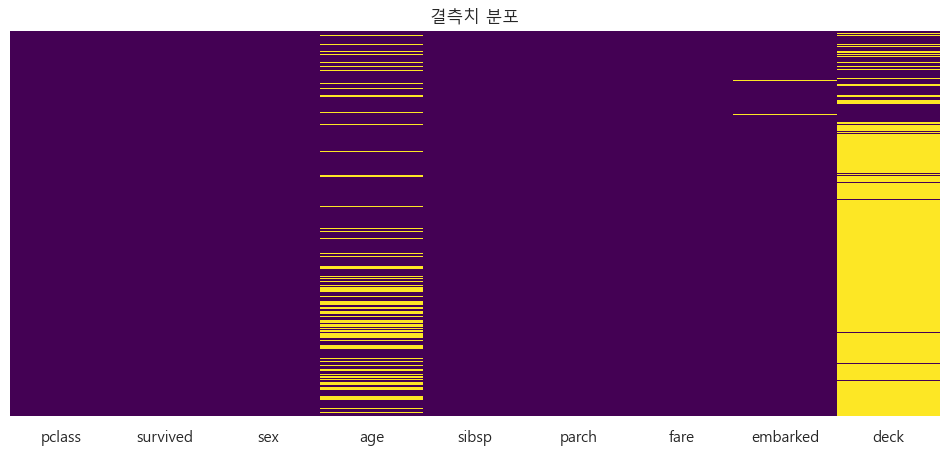

In [6]:
plt.figure(figsize=(12, 5))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap='viridis')
# seaborn lib 사용하여 matplotlib 차트 그림. (히트맵)
# 결과를 보면 deck 대부분의 값이 비어 있음을 알 수 있음

plt.title('결측치 분포')
plt.show()

**처리 전략**
- `deck`: 약 77% 결측 => 컬럼 제거 후 대체 변수 생성 (객실 자체의 유무는 상관관계 존재 가능)
- `age`: 약 20% 결측 => 성별·객실등급(`sex`, `pclass`) 그룹별 중앙값으로 대체
- `embarked`: 2건 => 탑승 항구, 최빈값으로 대체 (범주형:문자열 변수)
- `fare`: 1건 => 객실등급별 중앙값으로 대체

In [7]:
# 나이 분포가 그룹별로 다른지 확인
# pclass == 승객 객실 등급 (1,2,3 등석)
df.groupby(['sex', 'pclass'])['age'].median().unstack()

pclass,1,2,3
sex,,,
female,36.0,28.0,22.0
male,42.0,29.5,25.0


In [8]:
df['has_deck'] = df['deck'].notna().astype(int)
df = df.drop(columns=['deck'])
# deck 은 has_deck, 즉 deck의 존재여부로 대체함
# notna() 를 사용해 존재여부 자체를 저장해 데이터 정제

df['age_missing'] = df['age'].isna().astype(int)
df['age'] = df['age'].fillna(df.groupby(['sex', 'pclass'])['age'].transform('median'))
# age_missing 컬럼에 해당 row(사람, record) 의 age가 비어있었는지 여부를 남김
# age_missing 으로 정보 추출한 후에는 age na,결측치를 중앙값으로 대체

df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0])
df['fare'] = df['fare'].fillna(df.groupby('pclass')['fare'].transform('median'))
# embarked, fare도 age와 같은 방식으로 대체 (embarked 는 최빈값으로 대체)

print(df.isnull().sum().sum(), '개 결측치 남음')

0 개 결측치 남음


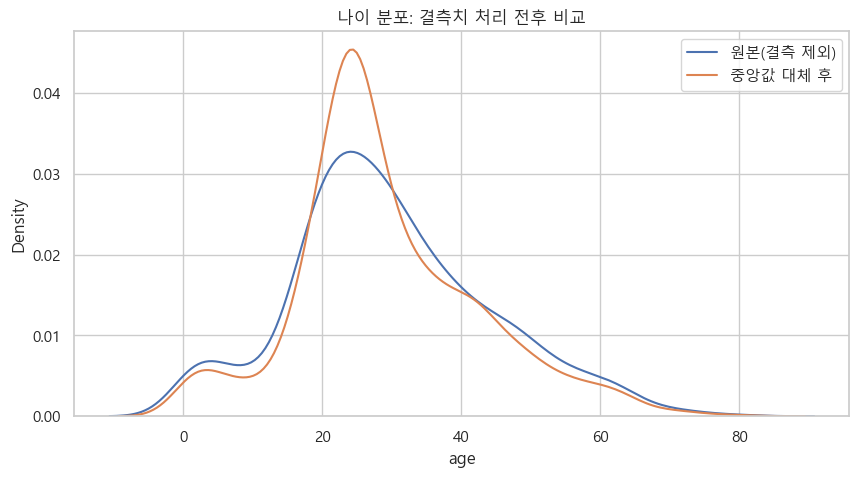

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.kdeplot(raw['age'].dropna(), label='원본(결측 제외)', ax=ax)
sns.kdeplot(df['age'], label='중앙값 대체 후', ax=ax)
# raw data와 비교해 보기 (Kernel Density Estimate, 부드러운 곡선 그래프)

ax.legend(); ax.set_title('나이 분포: 결측치 처리 전후 비교')
plt.show()
# 그래프를 보면 중앙값으로 대체함 => 가운데 봉우리가 더 뾰족해짐 (처리 후)

## 4. 이상치 확인

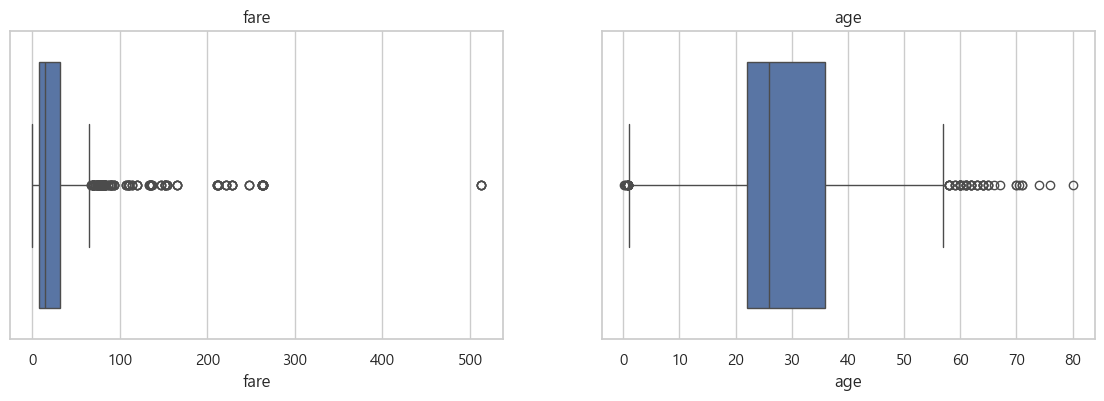

,pclass,fare,survived
49,1,512.3292,1
50,1,512.3292,1
302,1,512.3292,1
183,1,512.3292,1
116,1,263.0000,1


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(x=df['fare'], ax=axes[0]); axes[0].set_title('fare')
sns.boxplot(x=df['age'], ax=axes[1]); axes[1].set_title('age')
plt.show()
# fare(요금), age 그래프 각각 draw

df.sort_values('fare', ascending=False)[['pclass', 'fare', 'survived']].head()
# 요금 상위 5명 확인 (512.. 인 record의 survived 는 모두 1임을 확인 가능)

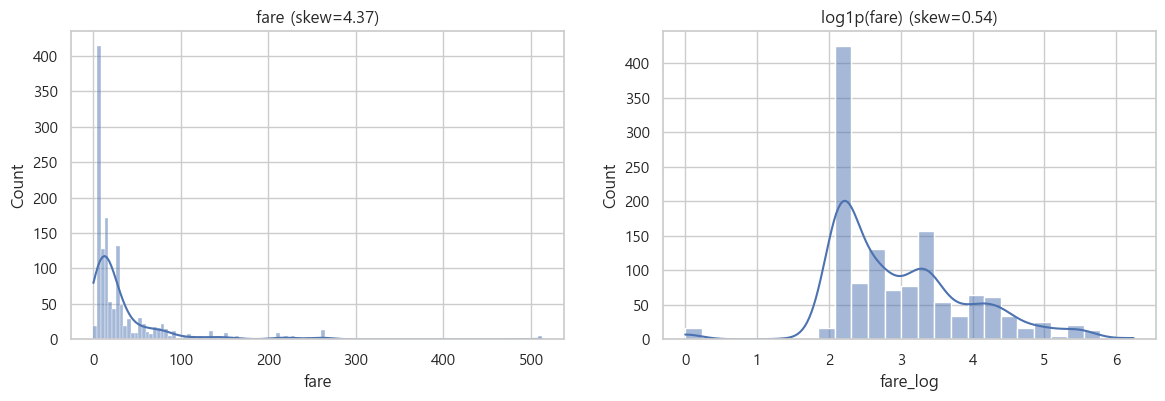

In [11]:
# fare는 오른쪽으로 크게 치우쳐 있어서 로그 변환 필요함 (scale조정해서 분석범위 좁혀 편하게만듦)
# 로그 적용 전후를 간단히 그래프로 비교 (적용 후가 고르게 퍼져 있어 처리하기 좋음)
df['fare_log'] = np.log1p(df['fare'])
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df['fare'], kde=True, ax=axes[0]); axes[0].set_title(f"fare (skew={df['fare'].skew():.2f})")
sns.histplot(df['fare_log'], kde=True, ax=axes[1]); axes[1].set_title(f"log1p(fare) (skew={df['fare_log'].skew():.2f})")
plt.show()

## 5. 파생 변수 & 범주형 처리

In [12]:
# 형제자매 배우자수 sibsp +  부모자녀수 parch + 본인(1) 더해서 총 인원수 구하고 라벨링
# 나이 그룹도 라벨링하여 보기 편하게 출력

df['family_size'] = df['sibsp'] + df['parch'] + 1
df['family_type'] = pd.cut(df['family_size'], bins=[0, 1, 4, 20], labels=['혼자', '소가족', '대가족'])
df['age_group'] = pd.cut(df['age'], bins=[0, 12, 18, 35, 60, 100], labels=['어린이', '청소년', '청년', '중년', '노년'], right=True)
df[['family_size', 'family_type', 'age', 'age_group']].head()
# 구간 경계 확인 (피드백 반영): right=True 라서 (0,12] (12,18] (18,35] ... 오른쪽 값 포함
# => 12세는 어린이, 18세는 청소년, 35세는 청년으로 분류됨 (의도한 분류)

,family_size,family_type,age,age_group
0,1,혼자,29.0000,청년
1,4,소가족,0.9167,어린이
2,4,소가족,2.0000,어린이
3,4,소가족,30.0000,청년
4,4,소가족,25.0000,청년


In [13]:
# 복사본으로 인코딩 작업
model_df = df.copy()
model_df['sex'] = model_df['sex'].map({'male': 0, 'female': 1})  # 처리하기 쉽게 male 0, female 1로 변경
model_df = pd.get_dummies(model_df, columns=['embarked', 'family_type', 'age_group'], drop_first=True, dtype=int)
# multi value 범주형 col => 원핫인코딩으로 바꾸어 처리하기 쉽게 함
model_df.head()

# 원본 값과 파생 변수가 같이 들어있으면 정보가 중복됨 (피드백 반영)
# age => age_group, fare => fare_log, family_size(sibsp+parch+1) => family_type 으로 대체했으므로 원본은 drop
model_df = model_df.drop(columns=['age', 'fare', 'sibsp', 'parch', 'family_size'])
model_df.head()

,pclass,survived,sex,has_deck,age_missing,fare_log,embarked_Q,embarked_S,family_type_소가족,family_type_대가족,age_group_청소년,age_group_청년,age_group_중년,age_group_노년
0,1,1,1,1,0,5.358177,0,1,0,0,0,1,0,0
1,1,1,0,1,0,5.027492,0,1,1,0,0,0,0,0
2,1,0,1,1,0,5.027492,0,1,1,0,0,0,0,0
3,1,0,0,1,0,5.027492,0,1,1,0,0,1,0,0
4,1,0,1,1,0,5.027492,0,1,1,0,0,1,0,0


In [14]:
model_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   pclass           1309 non-null   int64  
 1   survived         1309 non-null   int64  
 2   sex              1309 non-null   int64  
 3   has_deck         1309 non-null   int64  
 4   age_missing      1309 non-null   int64  
 5   fare_log         1309 non-null   float64
 6   embarked_Q       1309 non-null   int64  
 7   embarked_S       1309 non-null   int64  
 8   family_type_소가족  1309 non-null   int64  
 9   family_type_대가족  1309 non-null   int64  
 10  age_group_청소년    1309 non-null   int64  
 11  age_group_청년     1309 non-null   int64  
 12  age_group_중년     1309 non-null   int64  
 13  age_group_노년     1309 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 143.3 KB


## 6. 생존 데이터 분석 (시각화)

전체 생존율: 38.2%



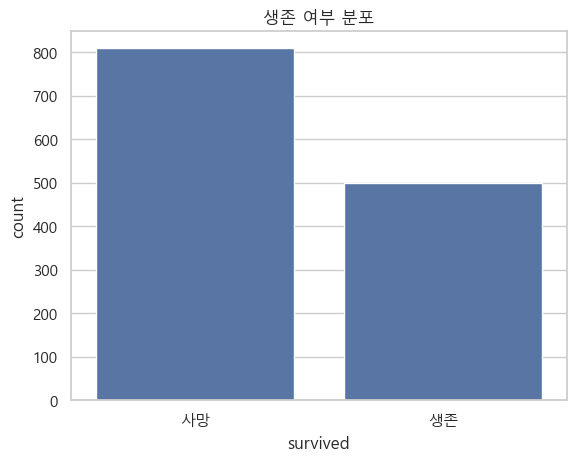

In [15]:
print('전체 생존율: {:.1%}\n'.format(df['survived'].mean()))
sns.countplot(data=df, x='survived')
plt.xticks([0, 1], ['사망', '생존']); plt.title('생존 여부 분포')
plt.show()

# 전체 생존율 파악

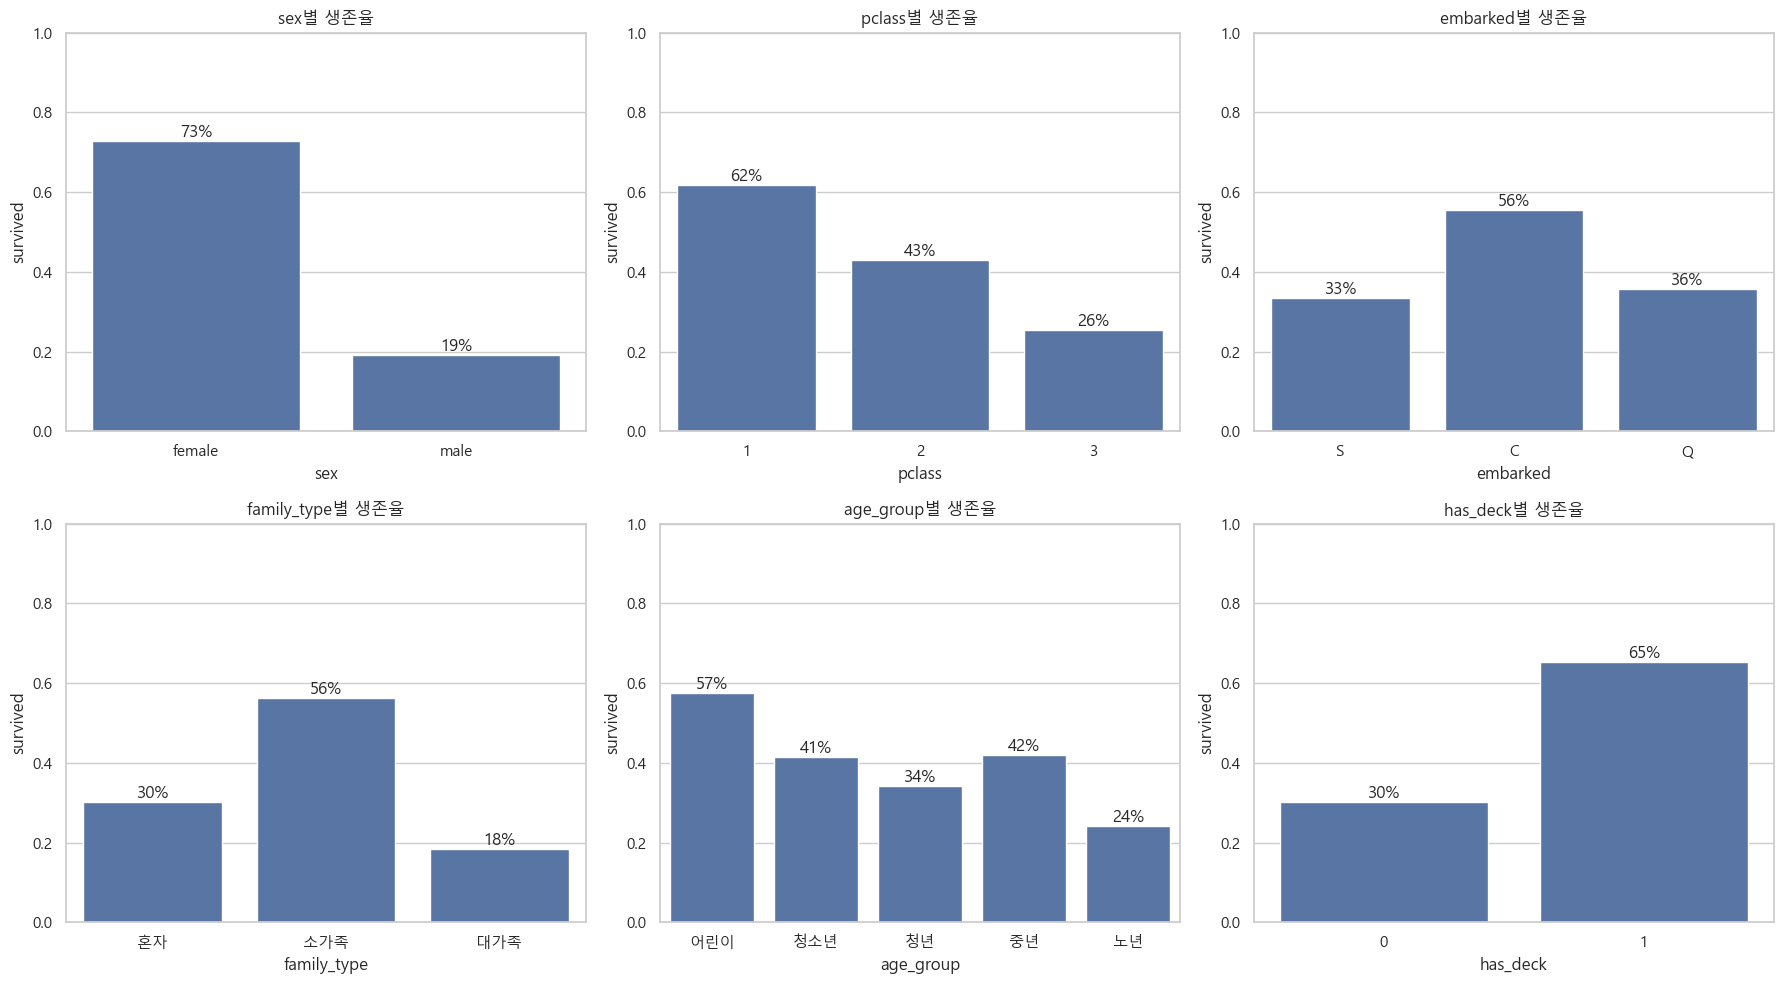

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, col in zip(axes.flat, ['sex', 'pclass', 'embarked', 'family_type', 'age_group', 'has_deck']):
    sns.barplot(data=df, x=col, y='survived', ax=ax, errorbar=None)
    ax.set_title(f'{col}별 생존율'); ax.set_ylim(0, 1)
    for p in ax.patches:
        ax.annotate(f'{p.get_height():.0%}', (p.get_x() + p.get_width()/2, p.get_height()), ha='center', va='bottom')
# 각 column 별 생존율 파악

plt.tight_layout()
plt.show()

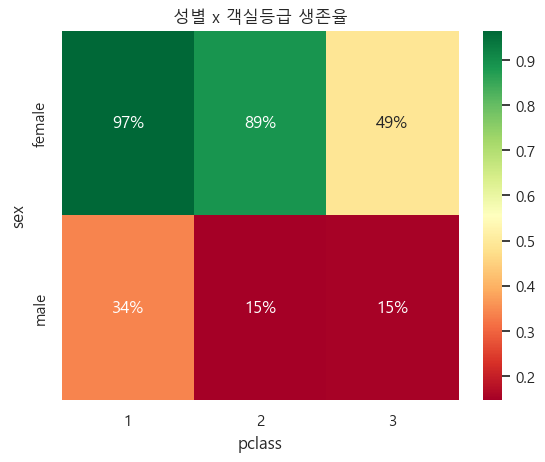

In [17]:
# 성별, 객실등급 생존률 히트맵 (성별row, 객실등급col, 생존여부-평균:생존율)
pivot = df.pivot_table(index='sex', columns='pclass', values='survived', aggfunc='mean')
sns.heatmap(pivot, annot=True, fmt='.0%', cmap='RdYlGn')
plt.title('성별 x 객실등급 생존율')
plt.show()

# 결과를 통해 객실 등급이 높을(1등급)일수록 생존율이 높음.
# 여성 생존율이 특히 높으며 1등급에서는 여성이 남성의 3배, 2등급에서는 약 6배 수준 차이 존재
# 개인 분석 : 어린이 생존율이 비교적 높았던 것을 함께 보아 여성, 어린이 먼저 대피시켰다는 추측도 가능

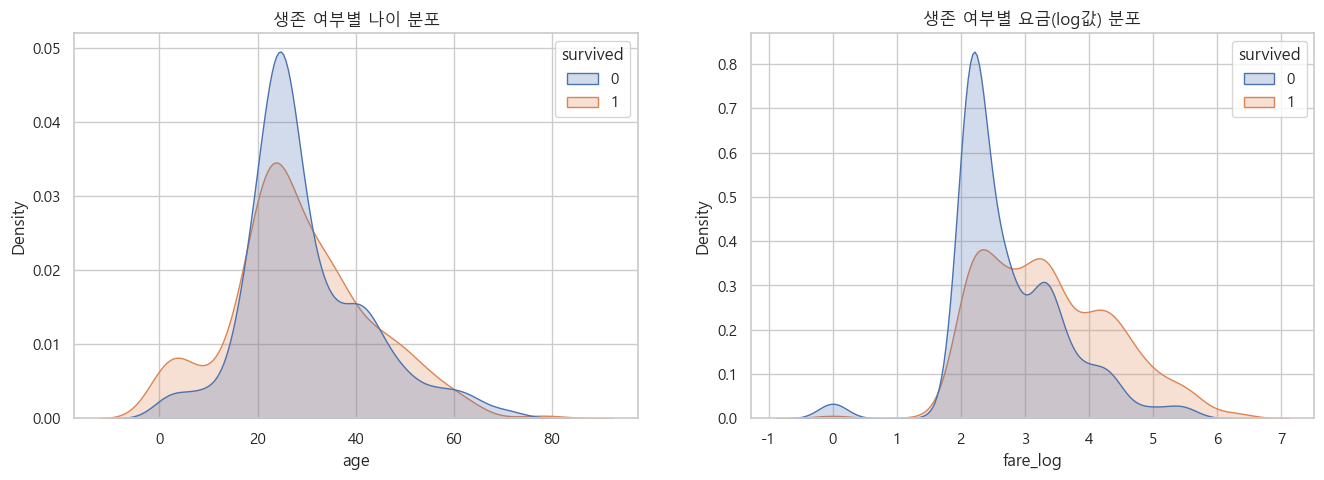

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.kdeplot(data=df, x='age', hue='survived', fill=True, common_norm=False, ax=axes[0])
axes[0].set_title('생존 여부별 나이 분포')

sns.kdeplot(data=df, x='fare_log', hue='survived', fill=True, common_norm=False, ax=axes[1])
axes[1].set_title('생존 여부별 요금(log값) 분포')

plt.show()
# 나이, 요금에 따른 생존여부 분포 파악

# 20대 청년층에서 가장 높고 (0,1모두 : 수 자체가 많음), 양끝단은 수 자체가 적음
# 20대 청년층에서는 사망자가 생존자보다 큰 폭으로 많음
# 어린이, 중장년층의 생존자 비율이 높다고 분석해 볼 수 있음

# 요금이 높을수록 생존자 비율이 높음을 알 수 있음
# log scale 요금값이 0인 부분은 생존자가 없는 것으로 볼 수 있으며,
# 6인 부분은 사망자가 없는 것으로 볼 수 있음 (요금순 정렬후 head한 결과로도 알 수 있었음)

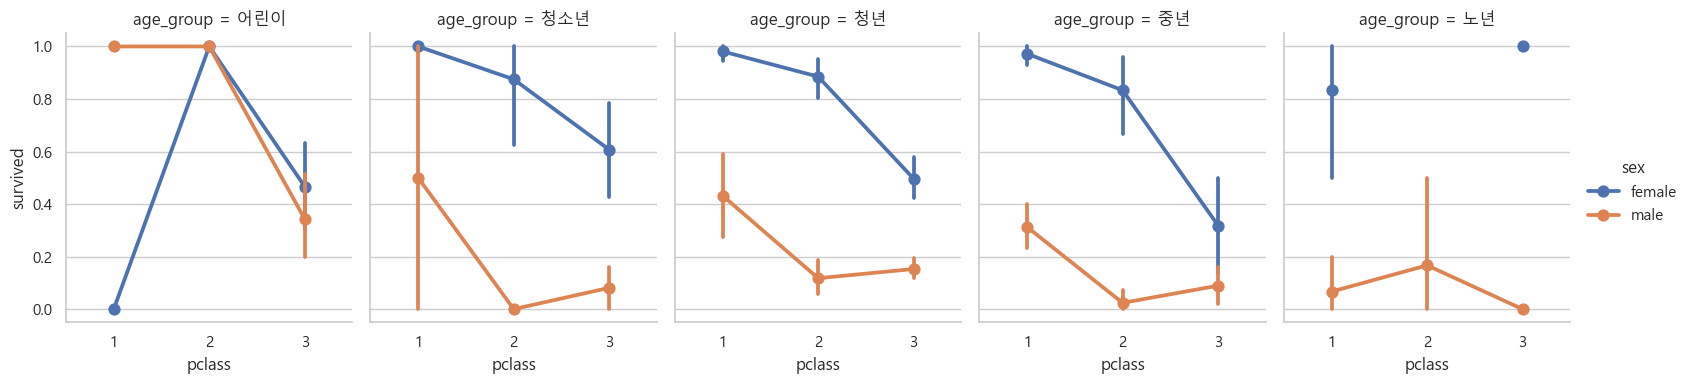

In [19]:
sns.catplot(data=df, x='pclass', y='survived', hue='sex', col='age_group', kind='point', height=4, aspect=0.8)
plt.show()

# catplot: categorical 그래프로 보기
# 나이 그룹별로 성별, pclass(객실 등급) 분석
# 세로선 == 오차막대 (표본이 적거나 편차 큰 경우 범위적으로 분석해야 하는 부분)

# 1등급객실에서 남성 어린이는 모두 생존, 여성 어린이는 모두 사망 (표본이 적을 수 있음) 등의 정보확인가능
# 전체적으로 성별에 따른 차이가 매우 두드러지는 것을 볼 수있음 (어린이 제외)
# 노년층 3등급 객실에서의 생존율이 1인 부분이 존재 => 특이한 데이터를 볼 수 있었음

## 7. 상관관계

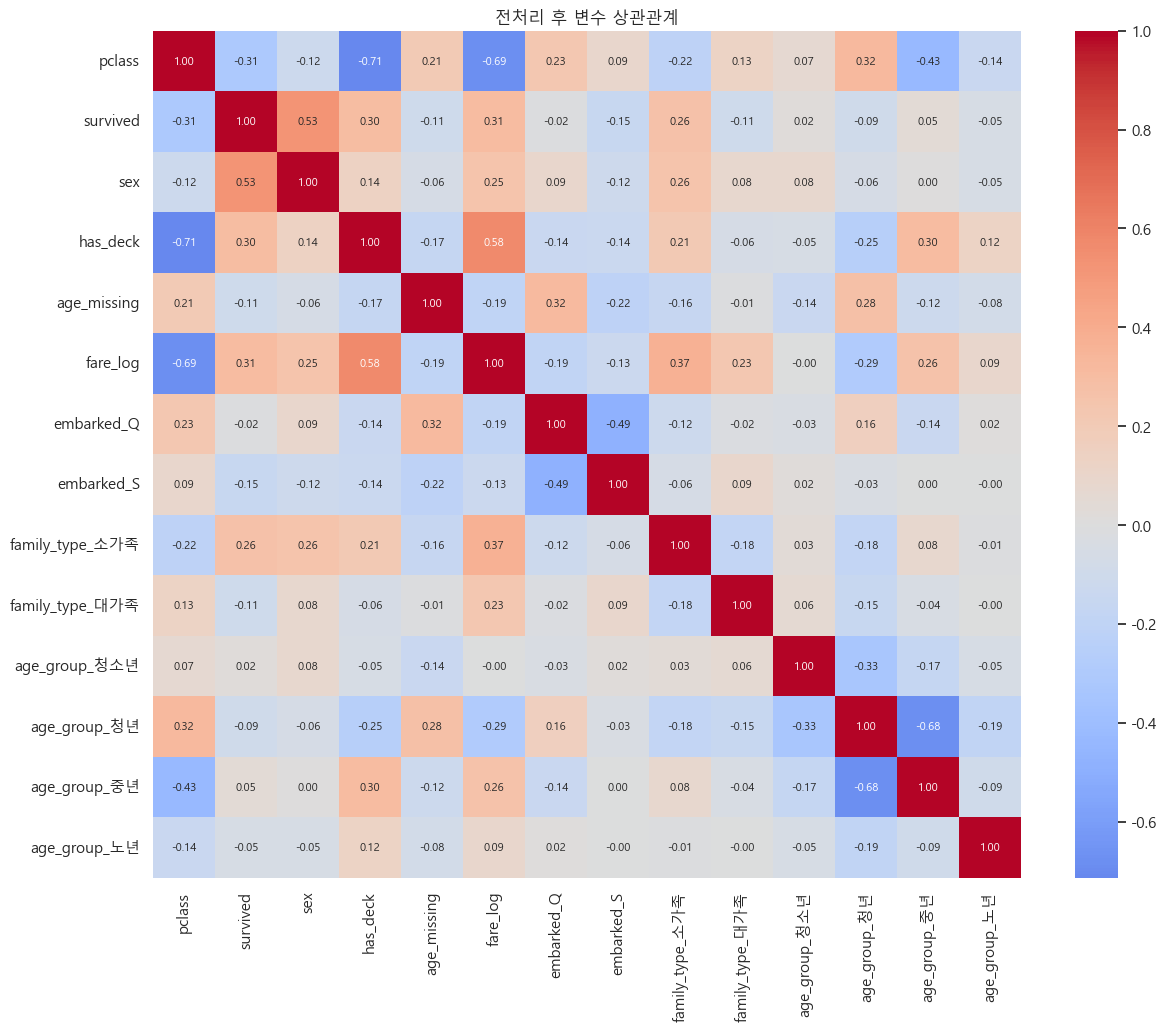

In [20]:
plt.figure(figsize=(14, 11))
corr = model_df.corr(numeric_only=True)

sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, annot_kws={'size': 8})
plt.title('전처리 후 변수 상관관계')
plt.show()

# 다중공선성 확인 (ML)
# 상관계수 계산 후 히트맵으로 시각화

# survived와 가장 관계가 큰 것은 성별
# (양의 상관관계: 클수록==여성(1)일수록 생존율 높음)

# survived와 가장 관계가 큰 것 중 음의 상관관계는 pclass
# (pclass값은 등급이 높을수록 숫자가 작음 == 높은 등급 객실 이용할수록 생존율높음)

# fare 높을수록, has_deck 이 1일수록 생존율 높음 (객실번호 없는 사람들 사망률 높은 경향)
# 소가족일수록 높은 경향

In [21]:
corr['survived'].drop('survived').sort_values(key=abs, ascending=False)

sex                0.528693
pclass            -0.312469
fare_log           0.305063
has_deck           0.302250
family_type_소가족    0.263658
embarked_S        -0.150542
age_missing       -0.107749
family_type_대가족   -0.105905
age_group_청년      -0.093524
age_group_노년      -0.046188
age_group_중년       0.046129
age_group_청소년      0.018939
embarked_Q        -0.016071
Name: survived, dtype: float64

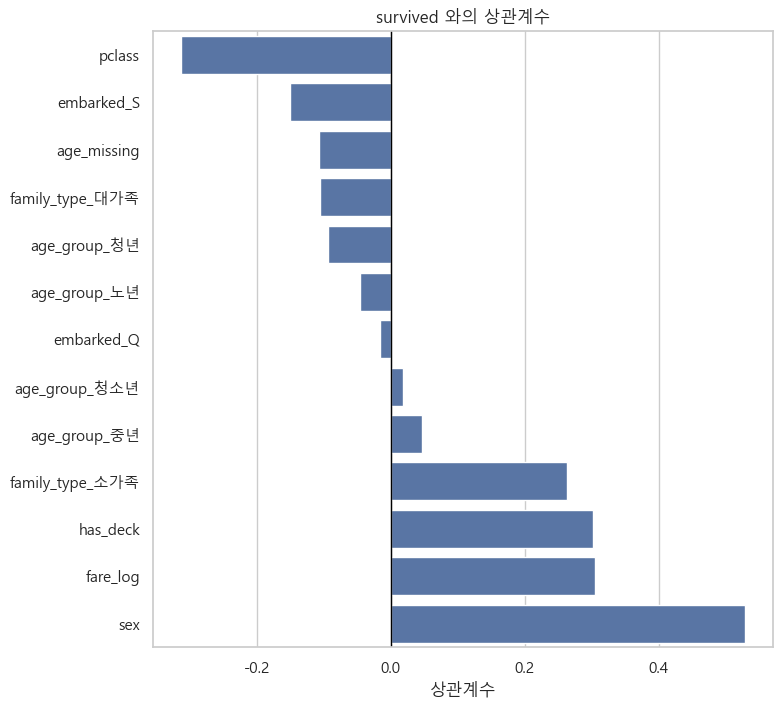

In [22]:
# survived 와의 상관계수만 정렬해서 막대그래프로 시각화 (피드백 반영)
surv_corr = corr['survived'].drop('survived').sort_values()

plt.figure(figsize=(8, 8))
sns.barplot(x=surv_corr.values, y=surv_corr.index, orient='h')
plt.axvline(0, color='black', linewidth=1)
plt.title('survived 와의 상관계수')
plt.xlabel('상관계수'); plt.ylabel('')
plt.show()

# 변수가 많은 히트맵 대신 타깃과의 관계만 한눈에 보기
# 양의 상관: sex(여성=1, 0.53) > fare_log, has_deck, 소가족 (0.26~0.31)
# 음의 상관: pclass(-0.31), embarked_S, 대가족 (객실 등급 숫자가 클수록 = 낮은 등급일수록 생존율 낮음)
# 원본/파생 중복 컬럼을 drop 한 뒤라서 히트맵도 이전보다 깔끔해짐

## 8. 정리
- **결측치**: `deck`(77%) 제거 + `has_deck` 파생, `age`는 성별·등급 그룹 중앙값 대치, `embarked` 최빈값, `fare` 등급별 중앙값 대치
- **범주형**: `sex` 라벨 인코딩, `embarked`/`family_type`/`age_group` 원-핫 인코딩, 데이터 누수 컬럼(`boat`, `body`) 제거
- **이상치/분포**: `fare` 오른쪽 치우침 → 로그 변환
- **생존 요인**: 여성 > 남성, 1등급 > 3등급, 어린이 생존률 높고, 소가족(2~4명) 생존률 높음, 객실정보 있는 승객 생존률 높음
- 성별과 객실등급이 생존과 가장 강한 관련
- 피드백 반영: 원본/파생 중복 컬럼 drop, age 구간 경계 명시, survived 상관계수 막대그래프 추가